# Loading data

In [ ]:
import pandas as pd

all_pr_df = pd.read_parquet("Data/all_pull_request.parquet")
human_pr_df_without_bots = pd.read_parquet("Data/human_pull_request_removed_bot_prs.parquet")
human_repos_urls_df_removed = pd.DataFrame({'repo_url' : human_pr_df_without_bots['repo_url'].unique()})
all_prs_from_repos_with_human_prs = all_pr_df.merge(human_repos_urls_df_removed, on='repo_url')

pr_comments_df = pd.read_parquet("Data/pr_comments.parquet")
pr_comments_from_repos_with_human_df = pr_comments_df[
    pr_comments_df['pr_id'].isin(all_prs_from_repos_with_human_prs['id'])
]

In [ ]:
human_pr_comments_df = pd.read_parquet("Data/human_pr_comments.parquet")
human_pr_comments_from_repos_with_human_df = human_pr_comments_df[
    human_pr_comments_df['pr_id'].isin(human_pr_df_without_bots['id'])
]

# Bot detection

### Full human_pr_comments dataset

In [ ]:
# Loading human_pr_comments.parquet
human_pr_comments = pd.read_parquet("Data/human_pr_comments.parquet")

# Filter user_type=="User"
human_user_filter = human_pr_comments['user_type'] == "User"

# Filter potential bots by username
human_bot_like_filter = human_pr_comments['user'].str.contains(r'bot|ci|copilot|ai|automation', case=False, na=False)

# Combine filters
human_suspected_bots = human_pr_comments[human_user_filter & human_bot_like_filter]

# Count the number of comments for each user
human_bot_counts = human_suspected_bots['user'].value_counts()

# Filter those who have a minimum of 10 comments
human_bot_counts_10plus = human_bot_counts[human_bot_counts >= 10]

# Sort records by comment count
human_bot_counts_10plus_sorted = human_bot_counts_10plus.sort_values(ascending=False)

# Display the first 50 suspects
display(human_bot_counts_10plus.head(50))

# Find Bots and change to BotOther
human_bots_users =  ['CLAassistant', 'codecov-commenter', 'pytorchmergebot', 'k8s-ci-robot', 'robobun', 'wolfSSL-Bot', 'vdaas-ci', 'lightdash-bot', 'typescript-bot', 'calcom-bot', 'azure-sdk', 'owidbot', 'modularbot','facebook-github-bot']

human_pr_comments.loc[human_pr_comments['user'].isin(human_bots_users), 'user_type'] = 'BotOther'

user
MayaRainer         38
jakebailey         23
calcom-bot         23
vdaas-ci           22
pytorchmergebot    19
mikomikotaishi     17
typescript-bot     17
lightdash-bot      11
Blaizzy            10
Name: count, dtype: int64

### Subset pr_comments_from_repos_with_human_df

In [7]:
# Filter user_type=="User"
pr_comments_from_repos_with_human_df_user_filter = pr_comments_from_repos_with_human_df['user_type'] == "User"

# Filter potential bots by username
pr_comments_from_repos_with_human_df_bot_like_filter = pr_comments_from_repos_with_human_df['user'].str.contains(r'bot|ci|copilot|ai|automation', case=False, na=False)

# Combine filters
pr_comments_from_repos_with_human_df_suspected_bots = pr_comments_from_repos_with_human_df[pr_comments_from_repos_with_human_df_user_filter & pr_comments_from_repos_with_human_df_bot_like_filter]

# Count the number of comments for each user
pr_comments_from_repos_with_human_df_bot_counts = pr_comments_from_repos_with_human_df_suspected_bots['user'].value_counts()

# Filter those who have a minimum of 10 comments
pr_comments_from_repos_with_human_df_bot_counts_10plus = pr_comments_from_repos_with_human_df_bot_counts[pr_comments_from_repos_with_human_df_bot_counts >= 10]

# Sort records by comment count
pr_comments_from_repos_with_human_df_bot_counts_10plus_sorted = pr_comments_from_repos_with_human_df_bot_counts_10plus.sort_values(ascending=False)

# Display the first 50 suspects
display(pr_comments_from_repos_with_human_df_bot_counts_10plus.head(50))

# Find Bots and change to BotOther
pr_comments_from_repos_with_human_bots_users =  ['CLAassistant', 'codecov-commenter', 'pytorchmergebot', 'k8s-ci-robot', 'robobun', 'wolfSSL-Bot', 'vdaas-ci', 'lightdash-bot', 'typescript-bot', 'calcom-bot', 'azure-sdk', 'owidbot', 'modularbot','facebook-github-bot']

pr_comments_from_repos_with_human_df.loc[pr_comments_from_repos_with_human_df['user'].isin(pr_comments_from_repos_with_human_bots_users), 'user_type'] = 'BotOther'

user
captainsafia       52
jakebailey         48
ian-at-airbyte     34
NoritakaIkeda      32
MayaRainer         27
vdaas-ci           25
wolfSSL-Bot        17
jairmyree          15
hairyhum           13
aishwaryabh        11
pytorchmergebot    11
Name: count, dtype: int64

### Subset human_pr_comments_from_repos_with_human_df

In [8]:
# Filter user_type=="User"
human_pr_comments_from_repos_with_human_df_user_filter = human_pr_comments_from_repos_with_human_df['user_type'] == "User"

# Filter potential bots by username
human_pr_comments_from_repos_with_human_df_bot_like_filter = human_pr_comments_from_repos_with_human_df['user'].str.contains(r'bot|ci|copilot|ai|automation', case=False, na=False)

# Combine filters
human_pr_comments_from_repos_with_human_df_suspected_bots = human_pr_comments_from_repos_with_human_df[human_pr_comments_from_repos_with_human_df_user_filter & human_pr_comments_from_repos_with_human_df_bot_like_filter]

# Count the number of comments for each user
human_pr_comments_from_repos_with_human_df_bot_counts = human_pr_comments_from_repos_with_human_df_suspected_bots['user'].value_counts()

# Filter those who have a minimum of 10 comments
human_pr_comments_from_repos_with_human_df_bot_counts_10plus = human_pr_comments_from_repos_with_human_df_bot_counts[human_pr_comments_from_repos_with_human_df_bot_counts >= 10]

# Sort records by comment count
human_pr_comments_from_repos_with_human_df_bot_counts_10plus_sorted = human_pr_comments_from_repos_with_human_df_bot_counts_10plus.sort_values(ascending=False)

# Display the first 50 suspects
display(human_pr_comments_from_repos_with_human_df_bot_counts_10plus.head(50))

# Find Bots and change to BotOther
human_pr_comments_from_repos_with_human_bots_users =  ['CLAassistant', 'codecov-commenter', 'pytorchmergebot', 'k8s-ci-robot', 'robobun', 'wolfSSL-Bot', 'vdaas-ci', 'lightdash-bot', 'typescript-bot', 'calcom-bot', 'azure-sdk', 'owidbot', 'modularbot','facebook-github-bot']

human_pr_comments_from_repos_with_human_df.loc[human_pr_comments_from_repos_with_human_df['user'].isin(human_pr_comments_from_repos_with_human_bots_users), 'user_type'] = 'BotOther'

user
MayaRainer         36
jakebailey         23
calcom-bot         23
vdaas-ci           22
pytorchmergebot    19
typescript-bot     17
mikomikotaishi     17
lightdash-bot      10
Blaizzy            10
Name: count, dtype: int64

# Empty PRs

In [9]:
all_ai_prs = all_prs_from_repos_with_human_prs["id"].unique()

# AI PRs with comments
ai_prs_with_comments = pr_comments_from_repos_with_human_df["pr_id"].unique()

# AI PRs without comments
ai_prs_no_comments = set(all_ai_prs) - set(ai_prs_with_comments)

ai_prs_no_comments_count = len(ai_prs_no_comments)
print(ai_prs_no_comments_count)
len(set(all_ai_prs))

2781


9616

In [10]:
all_human_prs = human_pr_df_without_bots["id"].unique()

# Human PRs with comments
human_prs_with_comments = human_pr_comments_from_repos_with_human_df["pr_id"].unique()

# human PRs without comments
human_prs_no_comments = set(all_human_prs) - set(human_prs_with_comments)

human_prs_no_comments_count = len(human_prs_no_comments)
human_prs_no_comments_count

1924

# Code review done by humans for PRs prepared by AI


### Regex + classification functions

In [11]:
import re

AGENT_PATTERN = r"(copilot|coderabbit|coderabbitai|bugbot|gemini|claude|devin|" \
                r"sourcery-ai|greptile|giselles-ai|giselle|pytorchbot|pytorchmergebot|sentry|zwave-js-bot|create-docs-giselles-ai)"

COMMAND_PATTERN = (
    r"(run|retry|recheck|rebase|review|summari[sz]e|start|continue|fix|resolve|"\
    r"merge|test|format|lint|sign|add|remove|update|rerun|check|verify|resume|"\
    r"generate|create|solve|clean|commit|pack|try|conflicts)"
)

AGENT_CMD_RE = re.compile(
    rf"""(?:^|\s)
    ([@\\\/]?{AGENT_PATTERN})
    [^.\n]*?
    \b{COMMAND_PATTERN}\b
    |
    \b{COMMAND_PATTERN}\b
    [^.\n]*?
    ([@\/\\]?{AGENT_PATTERN})
    """,
    re.IGNORECASE | re.VERBOSE,
)

STARTS_WITH_AGENT = re.compile(
    rf"""
    ^[@/ ]?{AGENT_PATTERN}
    """,
    re.IGNORECASE | re.VERBOSE,
)

OTHER_COMMANDS = re.compile(
    r"^[/#!@\[\\](azp|check-enforcer|easycla|run|rebase|build-deploy-preview|backport|autoformat|test|bump-version|ci|ba-|format-|poe|"\
    r"cherrypick|huppy|poetry-|ok-|queue-|ci-|fix-|engineer|deploypr|update-|format|checkenforcer|approve-|review|gogoeditdiff"\
    r"|microsoft-github-policy-service|intelci|gpu)",
    re.IGNORECASE | re.VERBOSE,
)
OTHER_COMMANDS_EXPL = re.compile(
    r"^(<\!-- buildkite-pr-bot-trigger-comment -->|\*\*\[chatops:help\]\*\*|\n\[\!\[coverage status\]|pre-commit\.ci autofix)", re.IGNORECASE)

WORKFLOW = re.compile(
    rf"^\s*(@\w+[\/\w\-]*\s+)?("

    # --- Status/Closure/Merge Commands ---
    rf"resolve merge conflict(s)?"
    rf"|merge (?:with master|main).*?"
    rf"|marking stale"
    rf"|closing (?:for now|as stale|out prs created during experiments with devin\.| \s*, integrated the temp fix in https?://\S+)"
    rf"|this pull request (?:was created as a test and will now be closed|has been marked as stale due to inactivity|has been closed due to lack of response).*?"
    rf"|this pr has been automatically marked as stale.*?"
    rf"|proactively closing this pull request\.\s*reopen if you need to after review\.\s*for any questions ping jwilcox\."
    rf"|force-merging, per conversation in slack\.\s*future iterations can resolve the test failures and\/or lack of robust integration test environment\."
    rf"|superseded by (?:pr #\d+|https?:\/\/\S+)"

    # --- Simple Bot/Action Commands ---
    rf"|lgtm!?"
    rf"|ok"
    rf"|done"
    rf"|good to go\."
    rf"|good bot"
    rf"|thank you(?: for|!| so)?"
    rf"|thanks"
    rf"|thx"
    rf"|crap"
    rf"|nope"
    rf"|bruh"
    rf"|\!sync"
    rf"|recheck"
    rf"|try (?:again|this)"
    rf"|please (?:try|retry|fix|update docs though)"
    rf"|check your solution again.*?"
    rf"|please test your latest changes by seeing if you're able to build\s*src\/core\/src\/core\.csproj"
    rf"|can you retry working on this pr\?"
    rf"|wake the fuck up samurai, we have prs to merge"

    # --- Fix/CI Commands ---
    rf"|fix lint (?:issue|failure(?: in ci)?)"
    rf"|lint (?:failure|ing fails)"
    rf"|fix merge issues"
    rf"|revert last commit"
    rf"|retest this please"
    rf"|fix failing (?:tests|spec tests)\."
    rf"|(?:build|run) (?:playground-composition|yarn change\" prerelease, |yarn lint:fix\" |yarn format\"|poetry lock and push it up|docs-build).*" # Broadened to include 'build'
    rf"|make sure that the rust formatter has been run against all changed files, as this is currently causing the build to fail\."
    rf"|i've fix with \[\w+\]\(https?:\/\/\S+\)"
    rf"|revert all changes in the archive directory"
    rf"|please remove the files under \.\/vendor\/\*"
    rf"|a bunch of files have been added due to some whitespaces, clean out them and only include the files that have changes relevant to this issue\."
    rf"|i think something went wrong in your last session, it seems like your changes weren't committed\. let's try again: please verify all of your changes and that the code works by running the json tests in stable and experimental mode"
    rf"|it looks like there are still compile errors\.\s*can you try again\?.*?"
    rf"|please format the code and commit it back to the pr"

    # --- Bot/System Status & Generic Error Messages ---
    rf"|build is still failing"
    rf"|test are failing"
    rf"|not working"
    rf"|doesn't work"
    rf"|the snippets failure is related to a preview feature\."
    rf"|looks like your session timed out\. try again\."
    rf"|already solved"
    rf"|not a good solution"
    rf"|the agent was blocked by configuration issues from accessing the necessary dependencies to successfully build and test\.\s*those are being fixed and we'll continue experimenting\."
    rf"|unbelievable\. you, \[subject name here\], must be the pride of \[subject hometown here\]!"
    rf"|it looks like the rebase was not correct\..*?"
    rf"|can one of the admins verify this patch?"

    # --- Action Requests on Documentation/Metadata ---
    rf"|add a bullet point to releasenotes\.md describing the change to our users"
    rf"|update change log"
    rf"|the description of the pr is not accurate anymore after all the changes, use examples from the new assert\.areequal tests and improve it to show some nice examples to the user\."
    rf"|make sure to follow the github pr title structure like we are doing for integrations"

    # --- Specific File Reversions ---
    rf"|revert all changes made to \"publicapi\.unshipped\.txt\" and then reapply changes to those files based on the api changes made in this pr"
    rf"|the publicapi\.unshipped\.txt files need to be fixed\s*in order to fix them can you\s*1\) revert all the changes to publicapi\.unshipped\.txt\s*2\) and then make whatever additions you need to make to them in order to fix the build"

    # --- User/Team Pings and Addressing Issues & Notifications ---
    rf"|@\w+[-\/\w]*(?: \([\w\s:]+\))?(?: ping)?"
    rf"|address #\d+"
    rf"|related to https?:\/\/\S+"
    rf"|i have read the cla document and i hereby sign the cla"
    rf"|duplicate"
    rf"|konfurikuto wo kaishou shite"
    rf"|looks good to me"
    rf"|fixed!?"
    rf"|good catch!?"
    rf"|nice catch!?"
    rf"|(:\w+:\s*)+.*"
    rf"|#\s*:x:\s*\[pr build\].*failed.*"
    rf"|can you (add more tests|take a look at the test failures).*\?"

    # --- Closing the pattern ---
    rf")\s*",
    re.IGNORECASE | re.DOTALL
)

AUTO_BOT = re.compile(
    rf"""
    ^\[approvalnotifier\]
    |^\s*hi\s+[@/]?{AGENT_PATTERN}\.\s+thanks\s+for\s+your\s+pr\..*
    |^\s*\*\*?\[WARNING:CONFLICT\]\*\*?.*
    |^\s*\*\*?\[FORMAT\]\*\*?.*
    |^\s*\*\*?API change check\*\*?.*
    """,
    re.IGNORECASE | re.VERBOSE,
)

def _matches(pattern, text: str) -> bool:
    return isinstance(text, str) and bool(pattern.search(text))


def is_agentic_ai_command(text: str) -> bool:
    return _matches(AGENT_CMD_RE, text) or _matches(STARTS_WITH_AGENT, text)

def is_other_command(text: str) -> bool:
    return _matches(OTHER_COMMANDS, text)

def is_auto_bot(text: str) -> bool:
    return _matches(AUTO_BOT, text) or _matches(OTHER_COMMANDS_EXPL, text)

def is_workflow(text: str) -> bool:
    return _matches(WORKFLOW, text)


def label_rev_type(text: str) -> str:
    if is_agentic_ai_command(text):
        return "agentic_cmd"
    if is_other_command(text) or is_auto_bot(text):
        return "bot"
    if is_workflow(text):
        return "workflow"
    return "review"

In [12]:
tests = [
    "/gemini review",
    "/azp",
    "/easycla",
    "text for rewiev purpose",
    "@copilot try again",
    "try again @copilot",
    "[approvalnotifier]",
    "hi @copilot. thanks for your pr.",
    "#gogoeditdiff",
    "@microsoft-github-policy-service",
    "<!-- buildkite-pr-bot-trigger-comment -->",
    "**[chatops:help]**",
    "\n[![coverage status]",
    "lgtm",
    "pre-commit.ci autofix",
    "!sync",
    "ok    ",
    "can one of the admins verify this patch?    ",
    "lgtm!",
    "/intelci: run",
    "@pytorchmergebot merge",
    "!gpu",
    "**[WARNING:CONFLICT]**",
    "\\azp",
    
]

for t in tests:
    print(t,"=>", label_rev_type(t))

/gemini review => agentic_cmd
/azp => bot
/easycla => bot
text for rewiev purpose => review
@copilot try again => agentic_cmd
try again @copilot => agentic_cmd
[approvalnotifier] => bot
hi @copilot. thanks for your pr. => bot
#gogoeditdiff => bot
@microsoft-github-policy-service => bot
<!-- buildkite-pr-bot-trigger-comment --> => bot
**[chatops:help]** => bot

[![coverage status] => bot
lgtm => workflow
pre-commit.ci autofix => bot
!sync => workflow
ok     => workflow
can one of the admins verify this patch?     => workflow
lgtm! => workflow
/intelci: run => bot
@pytorchmergebot merge => agentic_cmd
!gpu => bot
**[WARNING:CONFLICT]** => bot
\azp => bot


### Comment classification

In [13]:
# mask for "real" users
m_human = human_pr_comments_from_repos_with_human_df["user_type"] == "User"
m_all = pr_comments_from_repos_with_human_df["user_type"] == "User"

# mask for "artificial" users
m_bot_human = human_pr_comments_from_repos_with_human_df["user_type"].isin(["Bot", "BotOther"])
m_bot = pr_comments_from_repos_with_human_df["user_type"].isin(["Bot", "BotOther"])

# error fix
human_pr_comments_from_repos_with_human_df = human_pr_comments_from_repos_with_human_df.copy()
pr_comments_from_repos_with_human_df = pr_comments_from_repos_with_human_df.copy()

# apply classifier only on those rows
human_pr_comments_from_repos_with_human_df.loc[m_human,"rev_type"] = human_pr_comments_from_repos_with_human_df.loc[m_human, "body"].apply(label_rev_type)
human_pr_comments_from_repos_with_human_df.loc[m_bot_human,"rev_type"] = human_pr_comments_from_repos_with_human_df.loc[m_bot_human, "body"].apply(label_rev_type)
pr_comments_from_repos_with_human_df.loc[m_all,"rev_type"] = pr_comments_from_repos_with_human_df.loc[m_all, "body"].apply(label_rev_type)
pr_comments_from_repos_with_human_df.loc[m_bot, "rev_type"] = (pr_comments_from_repos_with_human_df.loc[m_bot, "body"].apply(label_rev_type))

In [14]:
human_pr_comments_from_repos_with_human_df['rev_type'].value_counts() / sum(m_human)

rev_type
review         1.763373
workflow       0.308704
agentic_cmd    0.142112
bot            0.052584
Name: count, dtype: float64

In [15]:
pr_comments_from_repos_with_human_df['rev_type'].value_counts() / sum(m_all)

rev_type
review         2.659270
agentic_cmd    0.699245
workflow       0.176582
bot            0.097419
Name: count, dtype: float64

In [16]:
pr_comments_from_repos_with_human_df['rev_type'].value_counts() / sum(m_bot)

rev_type
review         1.010163
agentic_cmd    0.265618
workflow       0.067077
bot            0.037006
Name: count, dtype: float64

In [54]:
pr_comments_from_repos_with_human_df[pr_comments_from_repos_with_human_df['user_type'] == 'User'].groupby(pr_comments_from_repos_with_human_df['rev_type']).size()

rev_type
agentic_cmd    1647
bot             543
review         3309
workflow        855
dtype: int64

In [55]:
sample_df_pr_comments = (
    pr_comments_from_repos_with_human_df[pr_comments_from_repos_with_human_df["user_type"] == "User"]
    .groupby("rev_type", group_keys=False)
    .apply(lambda x: x.sample(min(50, len(x)), random_state=313022))
    .reset_index(drop=True)
)

/tmp/ipykernel_1872578/3449326657.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min(50, len(x)), random_state=313022))


In [56]:
sample_df_pr_comments = sample_df_pr_comments.rename(columns={
    "body": "text",
    "rev_type": "predicted_label"
})

sample_df_pr_comments["gold_label"] = ""

In [ ]:
sample_df_pr_comments[["text", "predicted_label", "gold_label"]].to_csv(
    "Evaluation/evaluation_sample_RQ2_pr_comments.csv",
    index=False
)

In [ ]:
df_eval_pr_comments = pd.read_csv("Evaluation/evaluation_sample_annotated_RQ2_pr_comments.csv")

print(df_eval_pr_comments.head())

                                                text predicted_label  \
0  @copilot :\n\nThe code does not even build. Tr...     agentic_cmd   
1  it was a nightmare to fix all the mistakes mad...     agentic_cmd   
2  @copilot  Run `eng/scripts/Export-Api.ps1 keyv...     agentic_cmd   
3         @copilot can you please fix the conflicts?     agentic_cmd   
4                                 @copilot try again     agentic_cmd   

    gold_label  
0  agentic_cmd  
1       review  
2  agentic_cmd  
3  agentic_cmd  
4  agentic_cmd  


In [59]:
from sklearn.metrics import confusion_matrix, classification_report

labels = ["agentic_cmd", "bot", "workflow", "review"]

cm = confusion_matrix(
    df_eval_pr_comments["gold_label"],
    df_eval_pr_comments["predicted_label"],
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=[f"true_{l}" for l in labels],
    columns=[f"pred_{l}" for l in labels]
)

print(cm_df)

                  pred_agentic_cmd  pred_bot  pred_workflow  pred_review
true_agentic_cmd                47         0              2            1
true_bot                         0        50              1            2
true_workflow                    1         0             43           16
true_review                      2         0              4           31


In [60]:
print(
    classification_report(
        df_eval_pr_comments["gold_label"],
        df_eval_pr_comments["predicted_label"],
        labels=labels,
        digits=3
    )
)

              precision    recall  f1-score   support

 agentic_cmd      0.940     0.940     0.940        50
         bot      1.000     0.943     0.971        53
    workflow      0.860     0.717     0.782        60
      review      0.620     0.838     0.713        37

    accuracy                          0.855       200
   macro avg      0.855     0.859     0.851       200
weighted avg      0.873     0.855     0.859       200



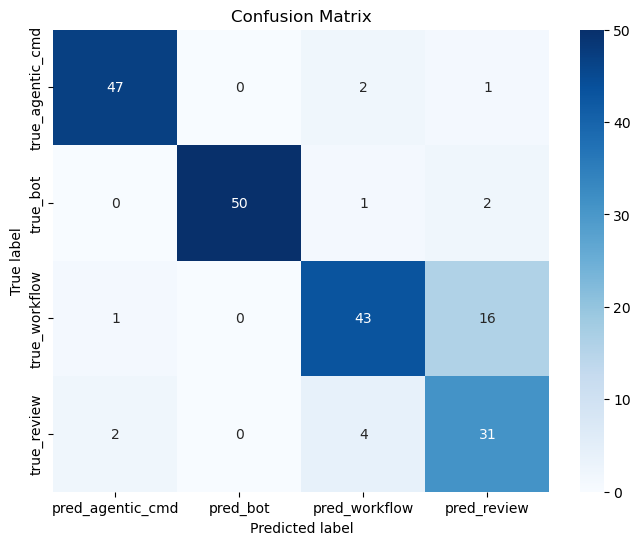

In [61]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))
sns.heatmap(cm_df, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.show()

In [62]:
human_pr_comments_from_repos_with_human_df[human_pr_comments_from_repos_with_human_df['user_type'] == 'User'].groupby(human_pr_comments_from_repos_with_human_df['rev_type']).size()

rev_type
agentic_cmd      72
bot             212
review         3017
workflow       1111
dtype: int64

In [63]:
sample_df_human_pr_comments = (
    human_pr_comments_from_repos_with_human_df[human_pr_comments_from_repos_with_human_df["user_type"] == "User"]
    .groupby("rev_type", group_keys=False)
    .apply(lambda x: x.sample(min(50, len(x)), random_state=313022))
    .reset_index(drop=True)
)

/tmp/ipykernel_1872578/322193798.py:4: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min(50, len(x)), random_state=313022))


In [64]:
sample_df_human_pr_comments = sample_df_human_pr_comments.rename(columns={
    "body": "text",
    "rev_type": "predicted_label"
})

sample_df_human_pr_comments["gold_label"] = ""

In [ ]:
sample_df_human_pr_comments[["text", "predicted_label", "gold_label"]].to_csv(
    "Evaluation/evaluation_sample_RQ2_human_pr_comments.csv",
    index=False
)

In [ ]:
df_eval_human_pr_comments = pd.read_csv("Evaluation/evaluation_sample_annotated_RQ2_human_pr_comments.csv")

print(df_eval_human_pr_comments.head())

                                                text predicted_label  \
0  it was a nightmare to fix all the mistakes mad...     agentic_cmd   
1  @copilot we want the policy file to be placed ...     agentic_cmd   
2  @copilot I updated the description. Make your ...     agentic_cmd   
3                       @copilot test \n\n --- \n\n      agentic_cmd   
4  @copilot check the CI workflow named `integrat...     agentic_cmd   

    gold_label  
0       review  
1  agentic_cmd  
2  agentic_cmd  
3  agentic_cmd  
4  agentic_cmd  


In [67]:
labels = ["agentic_cmd", "bot", "workflow", "review"]

cm_human = confusion_matrix(
    df_eval_human_pr_comments["gold_label"],
    df_eval_human_pr_comments["predicted_label"],
    labels=labels
)

cm_df_human = pd.DataFrame(
    cm_human,
    index=[f"true_{l}" for l in labels],
    columns=[f"pred_{l}" for l in labels]
)

print(cm_df_human)

                  pred_agentic_cmd  pred_bot  pred_workflow  pred_review
true_agentic_cmd                48         0              2            1
true_bot                         0        50              1            3
true_workflow                    1         0             43           19
true_review                      1         0              4           27


In [68]:
print(
    classification_report(
        df_eval_human_pr_comments["gold_label"],
        df_eval_human_pr_comments["predicted_label"],
        labels=labels,
        digits=3
    )
)

              precision    recall  f1-score   support

 agentic_cmd      0.960     0.941     0.950        51
         bot      1.000     0.926     0.962        54
    workflow      0.860     0.683     0.761        63
      review      0.540     0.844     0.659        32

    accuracy                          0.840       200
   macro avg      0.840     0.848     0.833       200
weighted avg      0.872     0.840     0.847       200



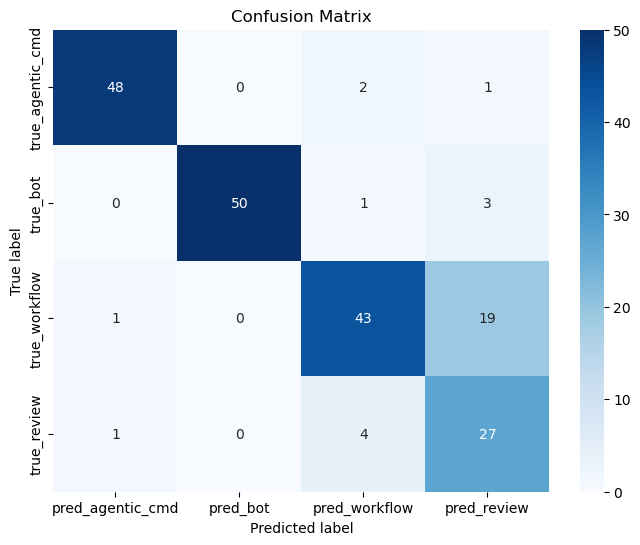

In [69]:
plt.figure(figsize=(8,6))
sns.heatmap(cm_df_human, annot=True, fmt="d", cmap="Blues")
plt.title("Confusion Matrix")
plt.ylabel("True label")
plt.xlabel("Predicted label")
plt.show()

### Statistical test

In [17]:
from scipy.stats import chi2_contingency

# Filtering
df_human = pr_comments_from_repos_with_human_df[
    (pr_comments_from_repos_with_human_df["user_type"] == "User")
    & pr_comments_from_repos_with_human_df["rev_type"].notna()
]

df_bot = pr_comments_from_repos_with_human_df[
    pr_comments_from_repos_with_human_df["user_type"].isin(["Bot", "BotOther"])
    & pr_comments_from_repos_with_human_df["rev_type"].notna()
]

# Counting rev_type categories for human and all other comments
counts_human = df_human["rev_type"].value_counts()
counts_bot   = df_bot["rev_type"].value_counts()

# Index matching
all_types = sorted(set(counts_human.index) | set(counts_bot.index))

table = pd.DataFrame({
    "human": counts_human.reindex(all_types, fill_value=0),
    "bot": counts_bot.reindex(all_types, fill_value=0)
})

print("Contingency table:")
display(table)

Contingency table:


,human,bot
rev_type,,
agentic_cmd,1647,2796
bot,543,76
review,3309,13588
workflow,855,267


In [18]:
chi2, p, dof, expected = chi2_contingency(table.T)

print(f"Chi-squared statistic: {chi2:.4f}")
print(f"p-value: {p}")
print(f"Number of degrees of freedom: {dof}")

display(pd.DataFrame(expected, columns=table.index, index=table.columns))

Chi-squared statistic: 3193.9688
p-value: 0.0
Number of degrees of freedom: 3


rev_type,agentic_cmd,bot,review,workflow
human,1223.119536,170.405355,4651.598198,308.876912
bot,3219.880464,448.594645,12245.401802,813.123088


### Statistics for Sankey diagrams

In [19]:
human_pr_comments_from_repos_with_human_df__human = human_pr_comments_from_repos_with_human_df[m_human]
human_pr_comments_from_repos_with_human_df__human__counts = human_pr_comments_from_repos_with_human_df__human['rev_type'].value_counts()
display(human_pr_comments_from_repos_with_human_df__human__counts)
print(sum(m_human))
len(human_pr_comments_from_repos_with_human_df) - sum(m_human)

rev_type
review         3017
workflow       1111
bot             212
agentic_cmd      72
Name: count, dtype: int64

4412


5589

In [20]:
pr_comments_from_repos_with_human_df__human = pr_comments_from_repos_with_human_df[m_all]
pr_comments_from_repos_with_human_df__human__counts = pr_comments_from_repos_with_human_df__human['rev_type'].value_counts()
display(pr_comments_from_repos_with_human_df__human__counts)
print(sum(m_all))
len(pr_comments_from_repos_with_human_df) - sum(m_all)

rev_type
review         3309
agentic_cmd    1647
workflow        855
bot             543
Name: count, dtype: int64

6354


16727

# Comments statistics for table

In [21]:
ai_comments_from_repos_with_human_agentic_comments_count = sum(pr_comments_from_repos_with_human_df["user_type"] != "User")
print(ai_comments_from_repos_with_human_agentic_comments_count)
human_comments_from_repos_with_human_agentic_comments_count = sum(human_pr_comments_from_repos_with_human_df["user_type"] != "User")
print(human_comments_from_repos_with_human_agentic_comments_count)

16727
5589


In [22]:
ai_comments_from_repos_with_human_human_comments_count = sum(pr_comments_from_repos_with_human_df["user_type"] == "User")
print(ai_comments_from_repos_with_human_human_comments_count)
human_comments_from_repos_with_human_human_comments_count = sum(human_pr_comments_from_repos_with_human_df["user_type"] == "User")
print(human_comments_from_repos_with_human_human_comments_count)

6354
4412


In [23]:
pr_comments_from_repos_with_human_df[pr_comments_from_repos_with_human_df['rev_type'] == 'bot']

,id,pr_id,user,user_id,user_type,created_at,body,rev_type
1117,3018988146,3187477285,jfversluis,939291,User,2025-06-30T12:35:48Z,/azp run MAUI-public,bot
1143,2894278025,3076083247,T-Gro,46543583,User,2025-05-20T12:47:00Z,/run fantomas,bot
1149,2901448984,3076083247,T-Gro,46543583,User,2025-05-22T14:29:00Z,/run fantomas,bot
1151,2901463015,3076083247,T-Gro,46543583,User,2025-05-22T14:32:47Z,/run fantomas,bot
1185,2973024463,3144116210,joshfree,1302850,User,2025-06-14T19:15:35Z,/check-enforcer override,bot
...,...,...,...,...,...,...,...,...
38814,2877718073,3060998787,devin-ai-integration[bot],158243242,Bot,2025-05-13T19:33:16Z,/bump-version type=minor,bot
38822,2877736008,3060998787,devin-ai-integration[bot],158243242,Bot,2025-05-13T19:37:23Z,/bump-version,bot
38825,2877745636,3060998787,theyueli,61070669,User,2025-05-13T19:40:27Z,"/bump-version type=patch changelog=""Add suppor...",bot
38827,2877751802,3060998787,devin-ai-integration[bot],158243242,Bot,2025-05-13T19:42:48Z,"/bump-version type=patch changelog=""Add suppor...",bot


### Statistics for data characterization regarding the number of processed pull requests

In [24]:
display(human_pr_comments_from_repos_with_human_df['pr_id'].unique())
display(pr_comments_from_repos_with_human_df['pr_id'].unique())

array([2336888723, 2447123365, 2332333882, ..., 2363711435, 2503287360,
       2566240535], shape=(3650,))

array([3234660269, 2915198291, 3223924413, ..., 2890563538, 2761443934,
       3047296744], shape=(6835,))

In [25]:
human_pr_comments_from_repos_with_human_df[(human_pr_comments_from_repos_with_human_df['rev_type'] == 'review') & (human_pr_comments_from_repos_with_human_df['user_type'] == 'User')]

,id,pr_id,user,user_id,user_type,created_at,body,rev_type
3,2790196496,2447123365,ryan953,187460,User,2025-04-09T15:56:50Z,> I don't know if this is [Sentry-wide](https:...,review
10,2758275418,2419106029,untitaker,837573,User,2025-03-27T14:30:49Z,note to self: the tests fail here because we a...,review
16,2993701768,2608720829,louis030195,25003283,User,2025-06-21T18:04:17Z,"<img width=""832"" alt=""image"" src=""https://gith...",review
17,2901512910,2536644442,louis030195,25003283,User,2025-05-22T14:47:09Z,thats rly cool\r\n\r\ncurious how the speed is...,review
19,2902881917,2536644442,louis030195,25003283,User,2025-05-22T23:56:24Z,can you delete old SDKs?,review
...,...,...,...,...,...,...,...,...
11595,2817710274,2470199127,jnsahaj,82111591,User,2025-04-21T06:03:04Z,I love some of these!\n\nGalactic Glitch has s...,review
11596,2819905718,2470199127,Vikaskumargd,7469181,User,2025-04-22T02:34:31Z,sure ☺️,review
11612,2842613662,2464758378,emosbaugh,371319,User,2025-04-30T16:44:22Z,I've tested this with the old code and it fail...,review
11615,2843006596,2464758378,emosbaugh,371319,User,2025-04-30T19:04:31Z,Sorry. I was stating the obvious I suppose. I ...,review


In [26]:
pr_comments_from_repos_with_human_df[(pr_comments_from_repos_with_human_df['rev_type'] == 'review') & (pr_comments_from_repos_with_human_df['user_type'] == 'User')]

,id,pr_id,user,user_id,user_type,created_at,body,rev_type
7,2720368428,2915784381,nickskalkin,3934579,User,2025-03-13T08:30:47Z,Co-authored-by: Claude \r\n😁,review
9,2721609147,2915784381,damassi,236943,User,2025-03-13T15:09:45Z,> Actually rewrite that commit and remove me a...,review
30,3051661645,3214876564,wtfsayo,82053242,User,2025-07-09T08:25:23Z,## ✅ All Review Feedback Addressed\n\nThank yo...,review
53,3105494837,3254649795,ChrisRackauckas,1814174,User,2025-07-23T02:55:41Z,"It went beyond the ""forget me not""",review
59,2981815481,3154662508,albertorizzi,48057685,User,2025-06-17T20:59:05Z,"Thank @Shpigford for this implementation, it'...",review
...,...,...,...,...,...,...,...,...
39098,2707879330,2904255373,benjaminshafii,11430621,User,2025-03-08T01:47:48Z,> ### 🤖 Devin AI Engineer\r\n> I'll be helping...,review
39107,2564708592,2762228850,shreysingla11,62649026,User,2024-12-29T12:25:49Z,"### Code Review Summary\n\nOverall, this PR ma...",review
39110,2693663048,2890563538,joaomdmoura,667063,User,2025-03-03T08:52:22Z,Disclaimer: This review was made by a crew of ...,review
39113,2564173971,2761443934,joaomdmoura,667063,User,2024-12-28T04:37:43Z,Disclaimer: This review was made by a crew of ...,review


### Characterization of review types at the PR level

In [27]:
def pr_summary(labels):
    unique = set(labels)
    return str(unique)

pr_labels_human = (
    human_pr_comments_from_repos_with_human_df[(human_pr_comments_from_repos_with_human_df['user_type'] == 'User')].groupby("pr_id")["rev_type"]
      .apply(pr_summary)
      .reset_index(name="pr_type")
)
pr_labels_all = (
    pr_comments_from_repos_with_human_df[(pr_comments_from_repos_with_human_df['user_type'] == 'User')].groupby("pr_id")["rev_type"]
      .apply(pr_summary)
      .reset_index(name="pr_type")
)

In [28]:
counts_human = pr_labels_human["pr_type"].value_counts()
print(counts_human)

pr_type
{'review'}                               925
{'workflow', 'review'}                   386
{'workflow'}                             247
{'bot'}                                   57
{'bot', 'review'}                         27
{'agentic_cmd'}                           27
{'bot', 'workflow', 'review'}             21
{'review', 'agentic_cmd'}                 11
{'workflow', 'review', 'agentic_cmd'}      7
{'bot', 'workflow'}                        6
{'workflow', 'agentic_cmd'}                4
Name: count, dtype: int64


In [29]:
counts_all = pr_labels_all["pr_type"].value_counts()
print(counts_all)

pr_type
{'review'}                                      1390
{'agentic_cmd'}                                  452
{'workflow'}                                     271
{'review', 'agentic_cmd'}                        198
{'workflow', 'review'}                           177
{'bot'}                                          117
{'workflow', 'review', 'agentic_cmd'}             68
{'bot', 'review'}                                 58
{'workflow', 'agentic_cmd'}                       47
{'bot', 'agentic_cmd'}                            41
{'bot', 'workflow', 'review'}                     26
{'bot', 'review', 'agentic_cmd'}                  21
{'bot', 'workflow', 'review', 'agentic_cmd'}      15
{'bot', 'workflow'}                               11
{'bot', 'workflow', 'agentic_cmd'}                 4
Name: count, dtype: int64


In [30]:
# No classical human part
print(counts_human[~counts_human.index.str.contains("review")].sum()/counts_human.sum())

# Only clasical
clasical_filter = counts_human.index.str.contains("{'review'}")
print(counts_human[clasical_filter].sum()/counts_human.sum())

# Classical + other
print(counts_human[counts_human.index.str.contains("review") & ~clasical_filter].sum()/counts_human.sum())

0.19848661233993015
0.5384167636786962
0.2630966239813737


In [31]:
# No classical human part
print(counts_all[~counts_all.index.str.contains("review")].sum()/counts_all.sum())

# Only clasical
clasical_filter = counts_all.index.str.contains("{'review'}")
print(counts_all[clasical_filter].sum()/counts_all.sum())

# Classical + other
print(counts_all[counts_all.index.str.contains("review") & ~clasical_filter].sum()/counts_all.sum())

0.32562154696132595
0.47997237569060774
0.1944060773480663


In [32]:
filtered_human = human_pr_comments_from_repos_with_human_df[
    (human_pr_comments_from_repos_with_human_df["user_type"] == "User") &
    (human_pr_comments_from_repos_with_human_df["rev_type"] == "review") 
]

top_bodies_human = (
    filtered_human["body"].str.lower()
    .value_counts()
    .head(50)     
)

#print(top_bodies_human)

In [33]:
filtered_all = pr_comments_from_repos_with_human_df[
    (pr_comments_from_repos_with_human_df["user_type"] == "User") &
    (pr_comments_from_repos_with_human_df["rev_type"] == "review") 
]

top_bodies_all = (
    filtered_all["body"].str.lower()
    .value_counts()
    .head(50)     
)

#print(top_bodies_all)

In [34]:
slash_counts_human = (
    human_pr_comments_from_repos_with_human_df[human_pr_comments_from_repos_with_human_df["body"].str.startswith("/", na=False) & (human_pr_comments_from_repos_with_human_df["rev_type"] == 'review')]["body"].value_counts()
)
#print(slash_counts_human)

In [35]:
slash_counts_all = (
    pr_comments_from_repos_with_human_df[pr_comments_from_repos_with_human_df["body"].str.startswith("/", na=False) & (pr_comments_from_repos_with_human_df["rev_type"] == 'review')]["body"].value_counts()
)
#print(slash_counts_all)

In [36]:
mask_human = human_pr_comments_from_repos_with_human_df["body"].str.startswith("/", na=False) & (human_pr_comments_from_repos_with_human_df["rev_type"] == "review")

# extract first token after '/'
first_word_human = human_pr_comments_from_repos_with_human_df.loc[mask_human, "body"].str.extract(r"^/(\S+)", expand=False)

slash_counts_human = first_word_human.value_counts()

#print(slash_counts_human)

In [37]:
mask_all = pr_comments_from_repos_with_human_df["body"].str.startswith("/", na=False) & (pr_comments_from_repos_with_human_df["rev_type"] == "review")

# extract first token after '/'
first_word_all = pr_comments_from_repos_with_human_df.loc[mask_all, "body"].str.extract(r"^/(\S+)", expand=False)

slash_counts_all = first_word_all.value_counts()

#print(slash_counts_all)

In [38]:
human_pr_comments_from_repos_with_human_df[human_pr_comments_from_repos_with_human_df['rev_type'] == 'agentic_cmd']

,id,pr_id,user,user_id,user_type,created_at,body,rev_type
2,2789767507,2447123365,gggritso,989898,User,2025-04-09T13:37:10Z,"I don't know if this is Sentry-wide, but the I...",agentic_cmd
45,2854188461,2501295276,coderabbitai[bot],136622811,Bot,2025-05-06T11:15:54Z,<!-- This is an auto-generated comment: summar...,agentic_cmd
53,2781704056,2441915356,coderabbitai[bot],136622811,Bot,2025-04-06T22:31:46Z,<!-- This is an auto-generated comment: summar...,agentic_cmd
55,2996304753,2611510009,coderabbitai[bot],136622811,Bot,2025-06-23T12:27:38Z,<!-- This is an auto-generated comment: summar...,agentic_cmd
56,2996312224,2611510009,edulelis,6522543,User,2025-06-23T12:29:37Z,@coderabbitai review,agentic_cmd
...,...,...,...,...,...,...,...,...
11577,2572071470,2261059610,coderabbitai[bot],136622811,Bot,2025-01-06T02:18:44Z,<!-- This is an auto-generated comment: summar...,agentic_cmd
11588,3117913025,2293305122,ericpgreen2,14206386,User,2025-07-25T13:55:11Z,@claude,agentic_cmd
11603,2892014677,2529557644,coderabbitai[bot],136622811,Bot,2025-05-19T19:07:05Z,<!-- This is an auto-generated comment: summar...,agentic_cmd
11631,2905953730,2541022658,codecov[bot],22429695,Bot,2025-05-23T22:37:08Z,## [Codecov](https://app.codecov.io/gh/livepee...,agentic_cmd


In [39]:
pr_comments_from_repos_with_human_df[pr_comments_from_repos_with_human_df['rev_type'] == 'agentic_cmd']

,id,pr_id,user,user_id,user_type,created_at,body,rev_type
1,3090154270,3234660269,Fank,1900106,User,2025-07-18T17:22:34Z,"claude budget reached, development is on hold ...",agentic_cmd
19,2991504795,3163243464,coderabbitai[bot],136622811,Bot,2025-06-20T12:56:07Z,<!-- This is an auto-generated comment: summar...,agentic_cmd
21,3051526209,3214876564,coderabbitai[bot],136622811,Bot,2025-07-09T07:39:39Z,<!-- This is an auto-generated comment: summar...,agentic_cmd
23,3051558554,3214876564,wtfsayo,82053242,User,2025-07-09T07:50:45Z,bugbot run,agentic_cmd
24,3051563644,3214876564,wtfsayo,82053242,User,2025-07-09T07:52:15Z,@claude @coderabbitai full review,agentic_cmd
...,...,...,...,...,...,...,...,...
39045,2914388328,3095454351,devin-ai-integration[bot],158243242,Bot,2025-05-27T23:02:23Z,### 🤖 Devin AI Engineer\n\nI'll be helping wit...,agentic_cmd
39048,2917733883,3095454351,github-actions[bot],41898282,Bot,2025-05-28T22:14:23Z,<!-- GENERATED-E2E-RESULTS -->\n## E2E results...,agentic_cmd
39062,2891388779,3073587664,devin-ai-integration[bot],158243242,Bot,2025-05-19T15:09:50Z,Devin is archived and cannot be woken up. Plea...,agentic_cmd
39089,2942423791,3119572928,devin-ai-integration[bot],158243242,Bot,2025-06-05T01:42:22Z,### 🤖 Devin AI Engineer\n\nI'll be helping wit...,agentic_cmd


# Table

### pr_comments_from_repos_with_human_df

In [40]:
num_pr = len(pr_comments_from_repos_with_human_df["pr_id"].unique())
total_reviews = len(pr_comments_from_repos_with_human_df)

reviews_per_pr = pr_comments_from_repos_with_human_df.groupby("pr_id").size()
mean_reviews = reviews_per_pr.mean()
median_reviews = reviews_per_pr.median()

rev_counts = pr_comments_from_repos_with_human_df["rev_type"].value_counts()

category_per_pr = (
    pr_comments_from_repos_with_human_df.groupby(["pr_id", "rev_type"])
               .size()
               .unstack(fill_value=0)
)

mean_per_category = category_per_pr.mean()
median_per_category = category_per_pr.median()

In [41]:
summary_table_repos_with_human = pd.DataFrame({
    "Category": [
        "Number of PRs",
        "Total number of reviews",
        "Evaluative",
        "Agentic Cmd",
        "Bot",
        "Workflow",
    ],
    "Total count": [
        num_pr,
        total_reviews,
        rev_counts.get("review", 0),
        rev_counts.get("agentic_cmd", 0),
        rev_counts.get("bot", 0),
        rev_counts.get("workflow", 0),
    ],
    "Mean per PR": [
        None,
        mean_reviews,
        mean_per_category.get("review", 0),
        mean_per_category.get("agentic_cmd", 0),
        mean_per_category.get("bot", 0),
        mean_per_category.get("workflow", 0),
    ],
    "Median per PR": [
        None,
        median_reviews,
        median_per_category.get("review", 0),
        median_per_category.get("agentic_cmd", 0),
        median_per_category.get("bot", 0),
        median_per_category.get("workflow", 0),
    ]
})

summary_table_repos_with_human

,Category,Total count,Mean per PR,Median per PR
0,Number of PRs,6835,NaN,NaN
1,Total number of reviews,23081,3.376884,2.0
2,Evaluative,16897,2.472129,2.0
3,Agentic Cmd,4443,0.650037,0.0
4,Bot,619,0.090563,0.0
5,Workflow,1122,0.164155,0.0


### human_pr_comments_from_repos_with_human_df

In [42]:
num_pr = len(human_pr_comments_from_repos_with_human_df["pr_id"].unique())
total_reviews = len(human_pr_comments_from_repos_with_human_df)

reviews_per_pr = human_pr_comments_from_repos_with_human_df.groupby("pr_id").size()
mean_reviews = reviews_per_pr.mean()
median_reviews = reviews_per_pr.median()

rev_counts = human_pr_comments_from_repos_with_human_df["rev_type"].value_counts()

category_per_pr = (
    human_pr_comments_from_repos_with_human_df.groupby(["pr_id", "rev_type"])
               .size()
               .unstack(fill_value=0)
)

mean_per_category = category_per_pr.mean()
median_per_category = category_per_pr.median()

In [43]:
summary_table_human_repos_with_human = pd.DataFrame({
    "Category": [
        "Number of PRs",
        "Total number of reviews",
        "Evaluative",
        "Agentic Cmd",
        "Bot",
        "Workflow",
    ],
    "Total count": [
        num_pr,
        total_reviews,
        rev_counts.get("review", 0),
        rev_counts.get("agentic_cmd", 0),
        rev_counts.get("bot", 0),
        rev_counts.get("workflow", 0),
    ],
    "Mean per PR": [
        None,
        mean_reviews,
        mean_per_category.get("review", 0),
        mean_per_category.get("agentic_cmd", 0),
        mean_per_category.get("bot", 0),
        mean_per_category.get("workflow", 0),
    ],
    "Median per PR": [
        None,
        median_reviews,
        median_per_category.get("review", 0),
        median_per_category.get("agentic_cmd", 0),
        median_per_category.get("bot", 0),
        median_per_category.get("workflow", 0),
    ]
})

summary_table_human_repos_with_human

,Category,Total count,Mean per PR,Median per PR
0,Number of PRs,3650,NaN,NaN
1,Total number of reviews,10001,2.740000,2.0
2,Evaluative,7780,2.131507,1.0
3,Agentic Cmd,627,0.171781,0.0
4,Bot,232,0.063562,0.0
5,Workflow,1362,0.373151,0.0


# Table v2 no 2

### Functions

In [44]:
m_comments = pr_comments_df["user_type"] == "User"
m_bot = pr_comments_df["user_type"].isin(["Bot", "BotOther"])

pr_comments_df = pr_comments_df.copy()
pr_comments_df.loc[m_comments,"rev_type"] = pr_comments_df.loc[m_comments, "body"].apply(label_rev_type)
pr_comments_df.loc[m_bot, "rev_type"] = (pr_comments_df.loc[m_bot, "body"].apply(label_rev_type))

In [49]:
def calculate_2nd_table(df):
    rev_types = {
        "Evaluative": "review",
        "Agentic Cmd": "agentic_cmd",
        "Bot": "bot",
        "Workflow": "workflow",
    }

    results = {}

    for label, rt in rev_types.items():
        df_rt = df[df["rev_type"] == rt]

        count = len(df_rt)

        per_pr = df_rt.groupby("pr_id").size()

        mean = per_pr.mean()
        std = per_pr.std()

        median, ci_low, ci_high = median_ci(per_pr)

        results[label] = {
            "count": count,
            "mean": mean,
            "std": std,
            "median": median,
            "ci_low": ci_low,
            "ci_high": ci_high,
        }

    return results


### pr_comments

#### full

In [50]:
columns = pd.MultiIndex.from_tuples([
    ("", "PR author"),
    ("", "Repository set"),
    ("Review status", "$C_0$"),
    ("Review status", "$C_{AI}$"),
    ("Review status", "$C_{human}$"),
    ("Human review categories", "Evaluative"),
    ("Human review categories", "Agentic"),
    ("Human review categories", "Bot"),
    ("Human review categories", "Workflow"),
])

pr_comments_df__human__counts = pd.Series({
    "review": 5767,
    "agentic_cmd": 3154,
    "workflow": 1408,
    "bot": 789
})

pr_comments_no_comments_count = 20621
pr_comments_human_comments_count = 11118
pr_comments_agentic_comments_count = 28004

ai_agent_r_pop_sum = pr_comments_agentic_comments_count + pr_comments_human_comments_count
ai_agent_r_sum = ai_comments_from_repos_with_human_agentic_comments_count + ai_comments_from_repos_with_human_human_comments_count
human_r_sum = human_comments_from_repos_with_human_agentic_comments_count + human_comments_from_repos_with_human_human_comments_count

def formattt(x, y):
    return f"{x} " + f"({round(x * 100 / y, 2)}\%)"


table2 = pd.DataFrame(columns=columns)
table2[("", "PR author")] = ["AI agent", "AI agent", "Human"]
table2[("", "Repository set")] = ["$R_{pop}$", "$R$", "$R$"]
table2[("Review status", "$C_0$")] = [
    formattt(pr_comments_no_comments_count, ai_agent_r_pop_sum),
    formattt(ai_prs_no_comments_count, ai_agent_r_sum),
    formattt(human_prs_no_comments_count, human_r_sum)
]
table2[("Review status", "$C_{AI}$")] = [
    formattt(pr_comments_agentic_comments_count, ai_agent_r_pop_sum),
    formattt(ai_comments_from_repos_with_human_agentic_comments_count, ai_agent_r_sum),
    formattt(human_comments_from_repos_with_human_agentic_comments_count, human_r_sum)
]
table2[("Review status", "$C_{human}$")] = [
    formattt(pr_comments_human_comments_count, ai_agent_r_pop_sum),
    formattt(ai_comments_from_repos_with_human_human_comments_count, ai_agent_r_sum),
    formattt(human_comments_from_repos_with_human_human_comments_count, human_r_sum)
]
table2[("Human review categories", "Evaluative")] = [
    formattt(pr_comments_df__human__counts["review"], ai_agent_r_pop_sum),
    formattt(pr_comments_from_repos_with_human_df__human__counts["review"], ai_agent_r_sum),
    formattt(human_pr_comments_from_repos_with_human_df__human__counts["review"], human_r_sum)
]
table2[("Human review categories", "Agentic")] = [
    formattt(pr_comments_df__human__counts["agentic_cmd"], ai_agent_r_pop_sum),
    formattt(pr_comments_from_repos_with_human_df__human__counts["agentic_cmd"], ai_agent_r_sum),
    formattt(human_pr_comments_from_repos_with_human_df__human__counts["agentic_cmd"], human_r_sum)
]
table2[("Human review categories", "Bot")] = [
    formattt(pr_comments_df__human__counts["bot"], ai_agent_r_pop_sum),
    formattt(pr_comments_from_repos_with_human_df__human__counts["bot"], ai_agent_r_sum),
    formattt(human_pr_comments_from_repos_with_human_df__human__counts["bot"], human_r_sum)
]
table2[("Human review categories", "Workflow")] = [
    formattt(pr_comments_df__human__counts["workflow"], ai_agent_r_pop_sum),
    formattt(pr_comments_from_repos_with_human_df__human__counts["workflow"], ai_agent_r_sum),
    formattt(human_pr_comments_from_repos_with_human_df__human__counts["workflow"], human_r_sum)
]
table2

Review status                                    \
  PR author Repository set            $C_0$         $C_{AI}$      $C_{human}$   
0  AI agent      $R_{pop}$  20621 (52.71\%)  28004 (71.58\%)  11118 (28.42\%)   
1  AI agent            $R$   2781 (12.05\%)  16727 (72.47\%)   6354 (27.53\%)   
2     Human            $R$   1924 (19.24\%)   5589 (55.88\%)   4412 (44.12\%)   

  Human review categories                                               
               Evaluative        Agentic           Bot        Workflow  
0          5767 (14.74\%)  3154 (8.06\%)  789 (2.02\%)    1408 (3.6\%)  
1          3309 (14.34\%)  1647 (7.14\%)  543 (2.35\%)     855 (3.7\%)  
2          3017 (30.17\%)    72 (0.72\%)  212 (2.12\%)  1111 (11.11\%)

In [51]:
print(table2.to_latex())

\begin{tabular}{llllllllll}
\toprule
 & \multicolumn{2}{r}{} & \multicolumn{3}{r}{Review status} & \multicolumn{4}{r}{Human review categories} \\
 & PR author & Repository set & $C_0$ & $C_{AI}$ & $C_{human}$ & Evaluative & Agentic & Bot & Workflow \\
\midrule
0 & AI agent & $R_{pop}$ & 20621 (52.71\%) & 28004 (71.58\%) & 11118 (28.42\%) & 5767 (14.74\%) & 3154 (8.06\%) & 789 (2.02\%) & 1408 (3.6\%) \\
1 & AI agent & $R$ & 2781 (12.05\%) & 16727 (72.47\%) & 6354 (27.53\%) & 3309 (14.34\%) & 1647 (7.14\%) & 543 (2.35\%) & 855 (3.7\%) \\
2 & Human & $R$ & 1924 (19.24\%) & 5589 (55.88\%) & 4412 (44.12\%) & 3017 (30.17\%) & 72 (0.72\%) & 212 (2.12\%) & 1111 (11.11\%) \\
\bottomrule
\end{tabular}



In [52]:
table_2nd_prc = calculate_2nd_table(pr_comments_df)

NameError: name 'median_ci' is not defined

In [ ]:
# Evaluative
eval_count_prc = table_2nd_prc["Evaluative"]["count"]
eval_mean_prc = table_2nd_prc["Evaluative"]["mean"]
eval_std_prc = table_2nd_prc["Evaluative"]["std"]
eval_median_prc = table_2nd_prc["Evaluative"]["median"]
eval_ci_low_prc = table_2nd_prc["Evaluative"]["ci_low"]
eval_ci_high_prc = table_2nd_prc["Evaluative"]["ci_high"]

# Agentic Cmd
cmd_count_prc = table_2nd_prc["Agentic Cmd"]["count"]
cmd_mean_prc = table_2nd_prc["Agentic Cmd"]["mean"]
cmd_std_prc = table_2nd_prc["Agentic Cmd"]["std"]
cmd_median_prc = table_2nd_prc["Agentic Cmd"]["median"]
cmd_ci_low_prc = table_2nd_prc["Agentic Cmd"]["ci_low"]
cmd_ci_high_prc = table_2nd_prc["Agentic Cmd"]["ci_high"]

# Bot
bot_count_prc = table_2nd_prc["Bot"]["count"]
bot_mean_prc = table_2nd_prc["Bot"]["mean"]
bot_std_prc = table_2nd_prc["Bot"]["std"]
bot_median_prc = table_2nd_prc["Bot"]["median"]
bot_ci_low_prc = table_2nd_prc["Bot"]["ci_low"]
bot_ci_high_prc = table_2nd_prc["Bot"]["ci_high"]

# Workflow
wf_count_prc = table_2nd_prc["Workflow"]["count"]
wf_mean_prc = table_2nd_prc["Workflow"]["mean"]
wf_std_prc = table_2nd_prc["Workflow"]["std"]
wf_median_prc = table_2nd_prc["Workflow"]["median"]
wf_ci_low_prc = table_2nd_prc["Workflow"]["ci_low"]
wf_ci_high_prc = table_2nd_prc["Workflow"]["ci_high"]


In [ ]:
print("Evaluative")
print("Count: \t\t", eval_count_prc)
print("Mean + std: \t", f"{eval_mean_prc:.2f} ± {eval_std_prc:.2f}")
print("Median + CI: \t", f"{eval_median_prc:.2f} + [{eval_ci_low_prc:.2f} - {eval_ci_high_prc:.2f}]")

print("\nAgentic Cmd")
print("Count: \t\t", cmd_count_prc)
print("Mean + std: \t", f"{cmd_mean_prc:.2f} ± {cmd_std_prc:.2f}")
print("Median + CI: \t", f"{cmd_median_prc:.2f} + [{cmd_ci_low_prc:.2f} - {cmd_ci_high_prc:.2f}]")

print("\nBot")
print("Count: \t\t", bot_count_prc)
print("Mean + std: \t", f"{bot_mean_prc:.2f} ± {bot_std_prc:.2f}")
print("Median + CI: \t", f"{bot_median_prc:.2f} + [{bot_ci_low_prc:.2f} - {bot_ci_high_prc:.2f}]")

print("\nWorkflow")
print("Count: \t\t", wf_count_prc)
print("Mean + std: \t", f"{wf_mean_prc:.2f} ± {wf_std_prc:.2f}")
print("Median + CI: \t", f"{wf_median_prc:.2f} + [{wf_ci_low_prc:.2f} - {wf_ci_high_prc:.2f}]")

Evaluative
Count: 		 27894
Mean + std: 	 2.42 ± 2.18
Median + CI: 	 2.00 + [2.00 - 2.00]

Agentic Cmd
Count: 		 8412
Mean + std: 	 1.80 ± 1.95
Median + CI: 	 1.00 + [1.00 - 1.00]

Bot
Count: 		 845
Mean + std: 	 1.91 ± 1.87
Median + CI: 	 1.00 + [1.00 - 1.00]

Workflow
Count: 		 1971
Mean + std: 	 1.44 ± 1.33
Median + CI: 	 1.00 + [1.00 - 1.00]


#### human

In [171]:
pr_comments_human = pr_comments_df[
    pr_comments_df["user_type"] == "User"
]

table_2nd_prc_human = calculate_2nd_table(pr_comments_human)

In [172]:
# Evaluative
eval_count_prc_human = table_2nd_prc_human["Evaluative"]["count"]
eval_mean_prc_human = table_2nd_prc_human["Evaluative"]["mean"]
eval_std_prc_human = table_2nd_prc_human["Evaluative"]["std"]
eval_median_prc_human = table_2nd_prc_human["Evaluative"]["median"]
eval_ci_low_prc_human = table_2nd_prc_human["Evaluative"]["ci_low"]
eval_ci_high_prc_human = table_2nd_prc_human["Evaluative"]["ci_high"]

# Agentic Cmd
cmd_count_prc_human = table_2nd_prc_human["Agentic Cmd"]["count"]
cmd_mean_prc_human = table_2nd_prc_human["Agentic Cmd"]["mean"]
cmd_std_prc_human = table_2nd_prc_human["Agentic Cmd"]["std"]
cmd_median_prc_human = table_2nd_prc_human["Agentic Cmd"]["median"]
cmd_ci_low_prc_human = table_2nd_prc_human["Agentic Cmd"]["ci_low"]
cmd_ci_high_prc_human = table_2nd_prc_human["Agentic Cmd"]["ci_high"]

# Bot
bot_count_prc_human = table_2nd_prc_human["Bot"]["count"]
bot_mean_prc_human = table_2nd_prc_human["Bot"]["mean"]
bot_std_prc_human = table_2nd_prc_human["Bot"]["std"]
bot_median_prc_human = table_2nd_prc_human["Bot"]["median"]
bot_ci_low_prc_human = table_2nd_prc_human["Bot"]["ci_low"]
bot_ci_high_prc_human = table_2nd_prc_human["Bot"]["ci_high"]

# Workflow
wf_count_prc_human = table_2nd_prc_human["Workflow"]["count"]
wf_mean_prc_human = table_2nd_prc_human["Workflow"]["mean"]
wf_std_prc_human = table_2nd_prc_human["Workflow"]["std"]
wf_median_prc_human = table_2nd_prc_human["Workflow"]["median"]
wf_ci_low_prc_human = table_2nd_prc_human["Workflow"]["ci_low"]
wf_ci_high_prc_human = table_2nd_prc_human["Workflow"]["ci_high"]


In [ ]:
print("Evaluative")
print("Count: \t\t", eval_count_prc_human)
print("Mean + std: \t", f"{eval_mean_prc_human:.2f} ± {eval_std_prc_human:.2f}")
print("Median + CI: \t", f"{eval_median_prc_human:.2f} + [{eval_ci_low_prc_human:.2f} - {eval_ci_high_prc_human:.2f}]")

print("\nAgentic Cmd")
print("Count: \t\t", cmd_count_prc_human)
print("Mean + std: \t", f"{cmd_mean_prc_human:.2f} ± {cmd_std_prc_human:.2f}")
print("Median + CI: \t", f"{cmd_median_prc_human:.2f} + [{cmd_ci_low_prc_human:.2f} - {cmd_ci_high_prc_human:.2f}]")

print("\nBot")
print("Count: \t\t", bot_count_prc_human)
print("Mean + std: \t", f"{bot_mean_prc_human:.2f} ± {bot_std_prc_human:.2f}")
print("Median + CI: \t", f"{bot_median_prc_human:.2f} + [{bot_ci_low_prc_human:.2f} - {bot_ci_high_prc_human:.2f}]")

print("\nWorkflow")
print("Count: \t\t", wf_count_prc_human)
print("Mean + std: \t", f"{wf_mean_prc_human:.2f} ± {wf_std_prc_human:.2f}")
print("Median + CI: \t", f"{wf_median_prc_human:.2f} + [{wf_ci_low_prc_human:.2f} - {wf_ci_high_prc_human:.2f}]")

Evaluative
Count: 		 6220
Mean + std: 	 1.69 ± 1.58
Median + CI: 	 1.00 + [1.00 - 1.00]

Agentic Cmd
Count: 		 3192
Mean + std: 	 2.01 ± 2.04
Median + CI: 	 1.00 + [1.00 - 1.00]

Bot
Count: 		 767
Mean + std: 	 1.83 ± 1.61
Median + CI: 	 1.00 + [1.00 - 1.00]

Workflow
Count: 		 1527
Mean + std: 	 1.38 ± 1.01
Median + CI: 	 1.00 + [1.00 - 1.00]


#### agentic

In [173]:
pr_comments_ai = pr_comments_df[
    pr_comments_df["user_type"].isin(["Bot", "BotOther"])
]

table_2nd_prc_agentic = calculate_2nd_table(pr_comments_ai)

In [174]:
# Evaluative
eval_count_prc_agentic = table_2nd_prc_agentic["Evaluative"]["count"]
eval_mean_prc_agentic = table_2nd_prc_agentic["Evaluative"]["mean"]
eval_std_prc_agentic = table_2nd_prc_agentic["Evaluative"]["std"]
eval_median_prc_agentic = table_2nd_prc_agentic["Evaluative"]["median"]
eval_ci_low_prc_agentic = table_2nd_prc_agentic["Evaluative"]["ci_low"]
eval_ci_high_prc_agentic = table_2nd_prc_agentic["Evaluative"]["ci_high"]

# Agentic Cmd
cmd_count_prc_agentic = table_2nd_prc_agentic["Agentic Cmd"]["count"]
cmd_mean_prc_agentic = table_2nd_prc_agentic["Agentic Cmd"]["mean"]
cmd_std_prc_agentic = table_2nd_prc_agentic["Agentic Cmd"]["std"]
cmd_median_prc_agentic = table_2nd_prc_agentic["Agentic Cmd"]["median"]
cmd_ci_low_prc_agentic = table_2nd_prc_agentic["Agentic Cmd"]["ci_low"]
cmd_ci_high_prc_agentic = table_2nd_prc_agentic["Agentic Cmd"]["ci_high"]

# Bot
bot_count_prc_agentic = table_2nd_prc_agentic["Bot"]["count"]
bot_mean_prc_agentic = table_2nd_prc_agentic["Bot"]["mean"]
bot_std_prc_agentic = table_2nd_prc_agentic["Bot"]["std"]
bot_median_prc_agentic = table_2nd_prc_agentic["Bot"]["median"]
bot_ci_low_prc_agentic = table_2nd_prc_agentic["Bot"]["ci_low"]
bot_ci_high_prc_agentic = table_2nd_prc_agentic["Bot"]["ci_high"]

# Workflow
wf_count_prc_agentic = table_2nd_prc_agentic["Workflow"]["count"]
wf_mean_prc_agentic = table_2nd_prc_agentic["Workflow"]["mean"]
wf_std_prc_agentic = table_2nd_prc_agentic["Workflow"]["std"]
wf_median_prc_agentic = table_2nd_prc_agentic["Workflow"]["median"]
wf_ci_low_prc_agentic = table_2nd_prc_agentic["Workflow"]["ci_low"]
wf_ci_high_prc_agentic = table_2nd_prc_agentic["Workflow"]["ci_high"]

In [175]:
print("Evaluative")
print("Count: \t\t", eval_count_prc_agentic)
print("Mean + std: \t", f"{eval_mean_prc_agentic:.2f} ± {eval_std_prc_agentic:.2f}")
print("Median + CI: \t", f"{eval_median_prc_agentic:.2f} + [{eval_ci_low_prc_agentic:.2f} - {eval_ci_high_prc_agentic:.2f}]")

print("\nAgentic Cmd")
print("Count: \t\t", cmd_count_prc_agentic)
print("Mean + std: \t", f"{cmd_mean_prc_agentic:.2f} ± {cmd_std_prc_agentic:.2f}")
print("Median + CI: \t", f"{cmd_median_prc_agentic:.2f} + [{cmd_ci_low_prc_agentic:.2f} - {cmd_ci_high_prc_agentic:.2f}]")

print("\nBot")
print("Count: \t\t", bot_count_prc_agentic)
print("Mean + std: \t", f"{bot_mean_prc_agentic:.2f} ± {bot_std_prc_agentic:.2f}")
print("Median + CI: \t", f"{bot_median_prc_agentic:.2f} + [{bot_ci_low_prc_agentic:.2f} - {bot_ci_high_prc_agentic:.2f}]")

print("\nWorkflow")
print("Count: \t\t", wf_count_prc_agentic)
print("Mean + std: \t", f"{wf_mean_prc_agentic:.2f} ± {wf_std_prc_agentic:.2f}")
print("Median + CI: \t", f"{wf_median_prc_agentic:.2f} + [{wf_ci_low_prc_agentic:.2f} - {wf_ci_high_prc_agentic:.2f}]")

Evaluative
Count: 		 21674
Mean + std: 	 2.09 ± 1.65
Median + CI: 	 2.00 + [2.00 - 2.00]

Agentic Cmd
Count: 		 5220
Mean + std: 	 1.31 ± 0.78
Median + CI: 	 1.00 + [1.00 - 1.00]

Bot
Count: 		 78
Mean + std: 	 2.05 ± 3.31
Median + CI: 	 1.00 + [1.00 - 1.00]

Workflow
Count: 		 444
Mean + std: 	 1.49 ± 2.00
Median + CI: 	 1.00 + [1.00 - 1.00]


### pr_comments_from_repos_with_human_df

#### full

In [ ]:
table_2nd_prc_rph = calculate_2nd_table(pr_comments_from_repos_with_human_df)

In [ ]:
# Evaluative
eval_count_prc_rph = table_2nd_prc_rph["Evaluative"]["count"]
eval_mean_prc_rph = table_2nd_prc_rph["Evaluative"]["mean"]
eval_std_prc_rph = table_2nd_prc_rph["Evaluative"]["std"]
eval_median_prc_rph = table_2nd_prc_rph["Evaluative"]["median"]
eval_ci_low_prc_rph = table_2nd_prc_rph["Evaluative"]["ci_low"]
eval_ci_high_prc_rph = table_2nd_prc_rph["Evaluative"]["ci_high"]

# Agentic Cmd
cmd_count_prc_rph = table_2nd_prc_rph["Agentic Cmd"]["count"]
cmd_mean_prc_rph = table_2nd_prc_rph["Agentic Cmd"]["mean"]
cmd_std_prc_rph = table_2nd_prc_rph["Agentic Cmd"]["std"]
cmd_median_prc_rph = table_2nd_prc_rph["Agentic Cmd"]["median"]
cmd_ci_low_prc_rph = table_2nd_prc_rph["Agentic Cmd"]["ci_low"]
cmd_ci_high_prc_rph = table_2nd_prc_rph["Agentic Cmd"]["ci_high"]

# Bot
bot_count_prc_rph = table_2nd_prc_rph["Bot"]["count"]
bot_mean_prc_rph = table_2nd_prc_rph["Bot"]["mean"]
bot_std_prc_rph = table_2nd_prc_rph["Bot"]["std"]
bot_median_prc_rph = table_2nd_prc_rph["Bot"]["median"]
bot_ci_low_prc_rph = table_2nd_prc_rph["Bot"]["ci_low"]
bot_ci_high_prc_rph = table_2nd_prc_rph["Bot"]["ci_high"]

# Workflow
wf_count_prc_rph = table_2nd_prc_rph["Workflow"]["count"]
wf_mean_prc_rph = table_2nd_prc_rph["Workflow"]["mean"]
wf_std_prc_rph = table_2nd_prc_rph["Workflow"]["std"]
wf_median_prc_rph = table_2nd_prc_rph["Workflow"]["median"]
wf_ci_low_prc_rph = table_2nd_prc_rph["Workflow"]["ci_low"]
wf_ci_high_prc_rph = table_2nd_prc_rph["Workflow"]["ci_high"]


In [ ]:
print("Evaluative")
print("Count: \t\t", eval_count_prc_rph)
print("Mean + std: \t", f"{eval_mean_prc_rph:.2f} ± {eval_std_prc_rph:.2f}")
print("Median + CI: \t", f"{eval_median_prc_rph:.2f} + [{eval_ci_low_prc_rph:.2f} - {eval_ci_high_prc_rph:.2f}]")

print("\nAgentic Cmd")
print("Count: \t\t", cmd_count_prc_rph)
print("Mean + std: \t", f"{cmd_mean_prc_rph:.2f} ± {cmd_std_prc_rph:.2f}")
print("Median + CI: \t", f"{cmd_median_prc_rph:.2f} + [{cmd_ci_low_prc_rph:.2f} - {cmd_ci_high_prc_rph:.2f}]")

print("\nBot")
print("Count: \t\t", bot_count_prc_rph)
print("Mean + std: \t", f"{bot_mean_prc_rph:.2f} ± {bot_std_prc_rph:.2f}")
print("Median + CI: \t", f"{bot_median_prc_rph:.2f} + [{bot_ci_low_prc_rph:.2f} - {bot_ci_high_prc_rph:.2f}]")

print("\nWorkflow")
print("Count: \t\t", wf_count_prc_rph)
print("Mean + std: \t", f"{wf_mean_prc_rph:.2f} ± {wf_std_prc_rph:.2f}")
print("Median + CI: \t", f"{wf_median_prc_rph:.2f} + [{wf_ci_low_prc_rph:.2f} - {wf_ci_high_prc_rph:.2f}]")

Evaluative
Count: 		 16883
Mean + std: 	 2.63 ± 2.35
Median + CI: 	 2.00 + [2.00 - 2.00]

Agentic Cmd
Count: 		 4463
Mean + std: 	 1.81 ± 1.89
Median + CI: 	 1.00 + [1.00 - 1.00]

Bot
Count: 		 619
Mean + std: 	 1.95 ± 2.04
Median + CI: 	 1.00 + [1.00 - 1.00]

Workflow
Count: 		 1116
Mean + std: 	 1.47 ± 1.55
Median + CI: 	 1.00 + [1.00 - 1.00]


#### human

In [ ]:
pr_comments_rwh_human = pr_comments_from_repos_with_human_df[
    pr_comments_from_repos_with_human_df["user_type"] == "User"
]

table_2nd_prc_rph_human = calculate_2nd_table(pr_comments_rwh_human)

In [ ]:
# Evaluative
eval_count_prc_rph_human = table_2nd_prc_rph_human["Evaluative"]["count"]
eval_mean_prc_rph_human = table_2nd_prc_rph_human["Evaluative"]["mean"]
eval_std_prc_rph_human = table_2nd_prc_rph_human["Evaluative"]["std"]
eval_median_prc_rph_human = table_2nd_prc_rph_human["Evaluative"]["median"]
eval_ci_low_prc_rph_human = table_2nd_prc_rph_human["Evaluative"]["ci_low"]
eval_ci_high_prc_rph_human = table_2nd_prc_rph_human["Evaluative"]["ci_high"]

# Agentic Cmd
cmd_count_prc_rph_human = table_2nd_prc_rph_human["Agentic Cmd"]["count"]
cmd_mean_prc_rph_human = table_2nd_prc_rph_human["Agentic Cmd"]["mean"]
cmd_std_prc_rph_human = table_2nd_prc_rph_human["Agentic Cmd"]["std"]
cmd_median_prc_rph_human = table_2nd_prc_rph_human["Agentic Cmd"]["median"]
cmd_ci_low_prc_rph_human = table_2nd_prc_rph_human["Agentic Cmd"]["ci_low"]
cmd_ci_high_prc_rph_human = table_2nd_prc_rph_human["Agentic Cmd"]["ci_high"]

# Bot
bot_count_prc_rph_human = table_2nd_prc_rph_human["Bot"]["count"]
bot_mean_prc_rph_human = table_2nd_prc_rph_human["Bot"]["mean"]
bot_std_prc_rph_human = table_2nd_prc_rph_human["Bot"]["std"]
bot_median_prc_rph_human = table_2nd_prc_rph_human["Bot"]["median"]
bot_ci_low_prc_rph_human = table_2nd_prc_rph_human["Bot"]["ci_low"]
bot_ci_high_prc_rph_human = table_2nd_prc_rph_human["Bot"]["ci_high"]

# Workflow
wf_count_prc_rph_human = table_2nd_prc_rph_human["Workflow"]["count"]
wf_mean_prc_rph_human = table_2nd_prc_rph_human["Workflow"]["mean"]
wf_std_prc_rph_human = table_2nd_prc_rph_human["Workflow"]["std"]
wf_median_prc_rph_human = table_2nd_prc_rph_human["Workflow"]["median"]
wf_ci_low_prc_rph_human = table_2nd_prc_rph_human["Workflow"]["ci_low"]
wf_ci_high_prc_rph_human = table_2nd_prc_rph_human["Workflow"]["ci_high"]


In [ ]:
print("Evaluative")
print("Count: \t\t", eval_count_prc_rph_human)
print("Mean + std: \t", f"{eval_mean_prc_rph_human:.2f} ± {eval_std_prc_rph_human:.2f}")
print("Median + CI: \t", f"{eval_median_prc_rph_human:.2f} + [{eval_ci_low_prc_rph_human:.2f} - {eval_ci_high_prc_rph_human:.2f}]")

print("\nAgentic Cmd")
print("Count: \t\t", cmd_count_prc_rph_human)
print("Mean + std: \t", f"{cmd_mean_prc_rph_human:.2f} ± {cmd_std_prc_rph_human:.2f}")
print("Median + CI: \t", f"{cmd_median_prc_rph_human:.2f} + [{cmd_ci_low_prc_rph_human:.2f} - {cmd_ci_high_prc_rph_human:.2f}]")

print("\nBot")
print("Count: \t\t", bot_count_prc_rph_human)
print("Mean + std: \t", f"{bot_mean_prc_rph_human:.2f} ± {bot_std_prc_rph_human:.2f}")
print("Median + CI: \t", f"{bot_median_prc_rph_human:.2f} + [{bot_ci_low_prc_rph_human:.2f} - {bot_ci_high_prc_rph_human:.2f}]")

print("\nWorkflow")
print("Count: \t\t", wf_count_prc_rph_human)
print("Mean + std: \t", f"{wf_mean_prc_rph_human:.2f} ± {wf_std_prc_rph_human:.2f}")
print("Median + CI: \t", f"{wf_median_prc_rph_human:.2f} + [{wf_ci_low_prc_rph_human:.2f} - {wf_ci_high_prc_rph_human:.2f}]")

Evaluative
Count: 		 3301
Mean + std: 	 1.70 ± 1.69
Median + CI: 	 1.00 + [1.00 - 1.00]

Agentic Cmd
Count: 		 1661
Mean + std: 	 1.94 ± 1.79
Median + CI: 	 1.00 + [1.00 - 1.00]

Bot
Count: 		 543
Mean + std: 	 1.85 ± 1.71
Median + CI: 	 1.00 + [1.00 - 1.00]

Workflow
Count: 		 849
Mean + std: 	 1.38 ± 1.10
Median + CI: 	 1.00 + [1.00 - 1.00]


#### agentic

In [ ]:
pr_comments_rwh_ai = pr_comments_from_repos_with_human_df[
    pr_comments_from_repos_with_human_df["user_type"].isin(["Bot", "BotOther"])
]

table_2nd_prc_rph_agentic = calculate_2nd_table(pr_comments_rwh_ai)

In [ ]:
# Evaluative
eval_count_prc_rph_agentic = table_2nd_prc_rph_agentic["Evaluative"]["count"]
eval_mean_prc_rph_agentic = table_2nd_prc_rph_agentic["Evaluative"]["mean"]
eval_std_prc_rph_agentic = table_2nd_prc_rph_agentic["Evaluative"]["std"]
eval_median_prc_rph_agentic = table_2nd_prc_rph_agentic["Evaluative"]["median"]
eval_ci_low_prc_rph_agentic = table_2nd_prc_rph_agentic["Evaluative"]["ci_low"]
eval_ci_high_prc_rph_agentic = table_2nd_prc_rph_agentic["Evaluative"]["ci_high"]

# Agentic Cmd
cmd_count_prc_rph_agentic = table_2nd_prc_rph_agentic["Agentic Cmd"]["count"]
cmd_mean_prc_rph_agentic = table_2nd_prc_rph_agentic["Agentic Cmd"]["mean"]
cmd_std_prc_rph_agentic = table_2nd_prc_rph_agentic["Agentic Cmd"]["std"]
cmd_median_prc_rph_agentic = table_2nd_prc_rph_agentic["Agentic Cmd"]["median"]
cmd_ci_low_prc_rph_agentic = table_2nd_prc_rph_agentic["Agentic Cmd"]["ci_low"]
cmd_ci_high_prc_rph_agentic = table_2nd_prc_rph_agentic["Agentic Cmd"]["ci_high"]

# Bot
bot_count_prc_rph_agentic = table_2nd_prc_rph_agentic["Bot"]["count"]
bot_mean_prc_rph_agentic = table_2nd_prc_rph_agentic["Bot"]["mean"]
bot_std_prc_rph_agentic = table_2nd_prc_rph_agentic["Bot"]["std"]
bot_median_prc_rph_agentic = table_2nd_prc_rph_agentic["Bot"]["median"]
bot_ci_low_prc_rph_agentic = table_2nd_prc_rph_agentic["Bot"]["ci_low"]
bot_ci_high_prc_rph_agentic = table_2nd_prc_rph_agentic["Bot"]["ci_high"]

# Workflow
wf_count_prc_rph_agentic = table_2nd_prc_rph_agentic["Workflow"]["count"]
wf_mean_prc_rph_agentic = table_2nd_prc_rph_agentic["Workflow"]["mean"]
wf_std_prc_rph_agentic = table_2nd_prc_rph_agentic["Workflow"]["std"]
wf_median_prc_rph_agentic = table_2nd_prc_rph_agentic["Workflow"]["median"]
wf_ci_low_prc_rph_agentic = table_2nd_prc_rph_agentic["Workflow"]["ci_low"]
wf_ci_high_prc_rph_agentic = table_2nd_prc_rph_agentic["Workflow"]["ci_high"]


In [ ]:
print("Evaluative")
print("Count: \t\t", eval_count_prc_rph_agentic)
print("Mean + std: \t", f"{eval_mean_prc_rph_agentic:.2f} ± {eval_std_prc_rph_agentic:.2f}")
print("Median + CI: \t", f"{eval_median_prc_rph_agentic:.2f} + [{eval_ci_low_prc_rph_agentic:.2f} - {eval_ci_high_prc_rph_agentic:.2f}]")

print("\nAgentic Cmd")
print("Count: \t\t", cmd_count_prc_rph_agentic)
print("Mean + std: \t", f"{cmd_mean_prc_rph_agentic:.2f} ± {cmd_std_prc_rph_agentic:.2f}")
print("Median + CI: \t", f"{cmd_median_prc_rph_agentic:.2f} + [{cmd_ci_low_prc_rph_agentic:.2f} - {cmd_ci_high_prc_rph_agentic:.2f}]")

print("\nBot")
print("Count: \t\t", bot_count_prc_rph_agentic)
print("Mean + std: \t", f"{bot_mean_prc_rph_agentic:.2f} ± {bot_std_prc_rph_agentic:.2f}")
print("Median + CI: \t", f"{bot_median_prc_rph_agentic:.2f} + [{bot_ci_low_prc_rph_agentic:.2f} - {bot_ci_high_prc_rph_agentic:.2f}]")

print("\nWorkflow")
print("Count: \t\t", wf_count_prc_rph_agentic)
print("Mean + std: \t", f"{wf_mean_prc_rph_agentic:.2f} ± {wf_std_prc_rph_agentic:.2f}")
print("Median + CI: \t", f"{wf_median_prc_rph_agentic:.2f} + [{wf_ci_low_prc_rph_agentic:.2f} - {wf_ci_high_prc_rph_agentic:.2f}]")

Evaluative
Count: 		 13582
Mean + std: 	 2.28 ± 1.83
Median + CI: 	 2.00 + [2.00 - 2.00]

Agentic Cmd
Count: 		 2802
Mean + std: 	 1.34 ± 0.81
Median + CI: 	 1.00 + [1.00 - 1.00]

Bot
Count: 		 76
Mean + std: 	 2.11 ± 3.45
Median + CI: 	 1.00 + [1.00 - 1.00]

Workflow
Count: 		 267
Mean + std: 	 1.57 ± 2.49
Median + CI: 	 1.00 + [1.00 - 1.00]


### human_pr_comments_from_repos_with_human_df

#### full

In [ ]:
table_2nd_hprc_rph = calculate_2nd_table(human_pr_comments_from_repos_with_human_df)

In [ ]:
# Evaluative
eval_count_hprc_rph = table_2nd_hprc_rph["Evaluative"]["count"]
eval_mean_hprc_rph = table_2nd_hprc_rph["Evaluative"]["mean"]
eval_std_hprc_rph = table_2nd_hprc_rph["Evaluative"]["std"]
eval_median_hprc_rph = table_2nd_hprc_rph["Evaluative"]["median"]
eval_ci_low_hprc_rph = table_2nd_hprc_rph["Evaluative"]["ci_low"]
eval_ci_high_hprc_rph = table_2nd_hprc_rph["Evaluative"]["ci_high"]

# Agentic Cmd
cmd_count_hprc_rph = table_2nd_hprc_rph["Agentic Cmd"]["count"]
cmd_mean_hprc_rph = table_2nd_hprc_rph["Agentic Cmd"]["mean"]
cmd_std_hprc_rph = table_2nd_hprc_rph["Agentic Cmd"]["std"]
cmd_median_hprc_rph = table_2nd_hprc_rph["Agentic Cmd"]["median"]
cmd_ci_low_hprc_rph = table_2nd_hprc_rph["Agentic Cmd"]["ci_low"]
cmd_ci_high_hprc_rph = table_2nd_hprc_rph["Agentic Cmd"]["ci_high"]

# Bot
bot_count_hprc_rph = table_2nd_hprc_rph["Bot"]["count"]
bot_mean_hprc_rph = table_2nd_hprc_rph["Bot"]["mean"]
bot_std_hprc_rph = table_2nd_hprc_rph["Bot"]["std"]
bot_median_hprc_rph = table_2nd_hprc_rph["Bot"]["median"]
bot_ci_low_hprc_rph = table_2nd_hprc_rph["Bot"]["ci_low"]
bot_ci_high_hprc_rph = table_2nd_hprc_rph["Bot"]["ci_high"]

# Workflow
wf_count_hprc_rph = table_2nd_hprc_rph["Workflow"]["count"]
wf_mean_hprc_rph = table_2nd_hprc_rph["Workflow"]["mean"]
wf_std_hprc_rph = table_2nd_hprc_rph["Workflow"]["std"]
wf_median_hprc_rph = table_2nd_hprc_rph["Workflow"]["median"]
wf_ci_low_hprc_rph = table_2nd_hprc_rph["Workflow"]["ci_low"]
wf_ci_high_hprc_rph = table_2nd_hprc_rph["Workflow"]["ci_high"]


In [ ]:
print("Evaluative")
print("Count: \t\t", eval_count_hprc_rph)
print("Mean + std: \t", f"{eval_mean_hprc_rph:.2f} ± {eval_std_hprc_rph:.2f}")
print("Median + CI: \t", f"{eval_median_hprc_rph:.2f} + [{eval_ci_low_hprc_rph:.2f} - {eval_ci_high_hprc_rph:.2f}]")

print("\nAgentic Cmd")
print("Count: \t\t", cmd_count_hprc_rph)
print("Mean + std: \t", f"{cmd_mean_hprc_rph:.2f} ± {cmd_std_hprc_rph:.2f}")
print("Median + CI: \t", f"{cmd_median_hprc_rph:.2f} + [{cmd_ci_low_hprc_rph:.2f} - {cmd_ci_high_hprc_rph:.2f}]")

print("\nBot")
print("Count: \t\t", bot_count_hprc_rph)
print("Mean + std: \t", f"{bot_mean_hprc_rph:.2f} ± {bot_std_hprc_rph:.2f}")
print("Median + CI: \t", f"{bot_median_hprc_rph:.2f} + [{bot_ci_low_hprc_rph:.2f} - {bot_ci_high_hprc_rph:.2f}]")

print("\nWorkflow")
print("Count: \t\t", wf_count_hprc_rph)
print("Mean + std: \t", f"{wf_mean_hprc_rph:.2f} ± {wf_std_hprc_rph:.2f}")
print("Median + CI: \t", f"{wf_median_hprc_rph:.2f} + [{wf_ci_low_hprc_rph:.2f} - {wf_ci_high_hprc_rph:.2f}]")

Evaluative
Count: 		 7780
Mean + std: 	 2.38 ± 2.45
Median + CI: 	 2.00 + [2.00 - 2.00]

Agentic Cmd
Count: 		 635
Mean + std: 	 1.13 ± 0.63
Median + CI: 	 1.00 + [1.00 - 1.00]

Bot
Count: 		 232
Mean + std: 	 1.89 ± 2.08
Median + CI: 	 1.00 + [1.00 - 1.00]

Workflow
Count: 		 1354
Mean + std: 	 1.65 ± 1.44
Median + CI: 	 1.00 + [1.00 - 1.00]


#### human

In [ ]:
human_pr_comments_rwh_human = human_pr_comments_from_repos_with_human_df[
    human_pr_comments_from_repos_with_human_df["user_type"] == "User"
]

table_2nd_hprc_rph_human = calculate_2nd_table(human_pr_comments_rwh_human)

In [ ]:
# Evaluative
eval_count_hprc_rph_human = table_2nd_hprc_rph_human["Evaluative"]["count"]
eval_mean_hprc_rph_human = table_2nd_hprc_rph_human["Evaluative"]["mean"]
eval_std_hprc_rph_human = table_2nd_hprc_rph_human["Evaluative"]["std"]
eval_median_hprc_rph_human = table_2nd_hprc_rph_human["Evaluative"]["median"]
eval_ci_low_hprc_rph_human = table_2nd_hprc_rph_human["Evaluative"]["ci_low"]
eval_ci_high_hprc_rph_human = table_2nd_hprc_rph_human["Evaluative"]["ci_high"]

# Agentic Cmd
cmd_count_hprc_rph_human = table_2nd_hprc_rph_human["Agentic Cmd"]["count"]
cmd_mean_hprc_rph_human = table_2nd_hprc_rph_human["Agentic Cmd"]["mean"]
cmd_std_hprc_rph_human = table_2nd_hprc_rph_human["Agentic Cmd"]["std"]
cmd_median_hprc_rph_human = table_2nd_hprc_rph_human["Agentic Cmd"]["median"]
cmd_ci_low_hprc_rph_human = table_2nd_hprc_rph_human["Agentic Cmd"]["ci_low"]
cmd_ci_high_hprc_rph_human = table_2nd_hprc_rph_human["Agentic Cmd"]["ci_high"]

# Bot
bot_count_hprc_rph_human = table_2nd_hprc_rph_human["Bot"]["count"]
bot_mean_hprc_rph_human = table_2nd_hprc_rph_human["Bot"]["mean"]
bot_std_hprc_rph_human = table_2nd_hprc_rph_human["Bot"]["std"]
bot_median_hprc_rph_human = table_2nd_hprc_rph_human["Bot"]["median"]
bot_ci_low_hprc_rph_human = table_2nd_hprc_rph_human["Bot"]["ci_low"]
bot_ci_high_hprc_rph_human = table_2nd_hprc_rph_human["Bot"]["ci_high"]

# Workflow
wf_count_hprc_rph_human = table_2nd_hprc_rph_human["Workflow"]["count"]
wf_mean_hprc_rph_human = table_2nd_hprc_rph_human["Workflow"]["mean"]
wf_std_hprc_rph_human = table_2nd_hprc_rph_human["Workflow"]["std"]
wf_median_hprc_rph_human = table_2nd_hprc_rph_human["Workflow"]["median"]
wf_ci_low_hprc_rph_human = table_2nd_hprc_rph_human["Workflow"]["ci_low"]
wf_ci_high_hprc_rph_human = table_2nd_hprc_rph_human["Workflow"]["ci_high"]


In [ ]:
print("Evaluative")
print("Count: \t\t", eval_count_hprc_rph_human)
print("Mean + std: \t", f"{eval_mean_hprc_rph_human:.2f} ± {eval_std_hprc_rph_human:.2f}")
print("Median + CI: \t", f"{eval_median_hprc_rph_human:.2f} + [{eval_ci_low_hprc_rph_human:.2f} - {eval_ci_high_hprc_rph_human:.2f}]")

print("\nAgentic Cmd")
print("Count: \t\t", cmd_count_hprc_rph_human)
print("Mean + std: \t", f"{cmd_mean_hprc_rph_human:.2f} ± {cmd_std_hprc_rph_human:.2f}")
print("Median + CI: \t", f"{cmd_median_hprc_rph_human:.2f} + [{cmd_ci_low_hprc_rph_human:.2f} - {cmd_ci_high_hprc_rph_human:.2f}]")

print("\nBot")
print("Count: \t\t", bot_count_hprc_rph_human)
print("Mean + std: \t", f"{bot_mean_hprc_rph_human:.2f} ± {bot_std_hprc_rph_human:.2f}")
print("Median + CI: \t", f"{bot_median_hprc_rph_human:.2f} + [{bot_ci_low_hprc_rph_human:.2f} - {bot_ci_high_hprc_rph_human:.2f}]")

print("\nWorkflow")
print("Count: \t\t", wf_count_hprc_rph_human)
print("Mean + std: \t", f"{wf_mean_hprc_rph_human:.2f} ± {wf_std_hprc_rph_human:.2f}")
print("Median + CI: \t", f"{wf_median_hprc_rph_human:.2f} + [{wf_ci_low_hprc_rph_human:.2f} - {wf_ci_high_hprc_rph_human:.2f}]")

Evaluative
Count: 		 3017
Mean + std: 	 2.19 ± 2.81
Median + CI: 	 1.00 + [1.00 - 1.00]

Agentic Cmd
Count: 		 80
Mean + std: 	 1.43 ± 1.11
Median + CI: 	 1.00 + [1.00 - 1.00]

Bot
Count: 		 212
Mean + std: 	 1.91 ± 2.15
Median + CI: 	 1.00 + [1.00 - 1.00]

Workflow
Count: 		 1103
Mean + std: 	 1.66 ± 1.44
Median + CI: 	 1.00 + [1.00 - 1.00]


#### agentic

In [ ]:
human_pr_comments_rwh_ai = human_pr_comments_from_repos_with_human_df[
    human_pr_comments_from_repos_with_human_df["user_type"].isin(["Bot", "BotOther"])
]

table_2nd_hprc_rph_agentic = calculate_2nd_table(human_pr_comments_rwh_ai)

In [ ]:
# Evaluative
eval_count_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Evaluative"]["count"]
eval_mean_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Evaluative"]["mean"]
eval_std_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Evaluative"]["std"]
eval_median_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Evaluative"]["median"]
eval_ci_low_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Evaluative"]["ci_low"]
eval_ci_high_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Evaluative"]["ci_high"]

# Agentic Cmd
cmd_count_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Agentic Cmd"]["count"]
cmd_mean_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Agentic Cmd"]["mean"]
cmd_std_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Agentic Cmd"]["std"]
cmd_median_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Agentic Cmd"]["median"]
cmd_ci_low_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Agentic Cmd"]["ci_low"]
cmd_ci_high_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Agentic Cmd"]["ci_high"]

# Bot
bot_count_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Bot"]["count"]
bot_mean_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Bot"]["mean"]
bot_std_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Bot"]["std"]
bot_median_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Bot"]["median"]
bot_ci_low_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Bot"]["ci_low"]
bot_ci_high_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Bot"]["ci_high"]

# Workflow
wf_count_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Workflow"]["count"]
wf_mean_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Workflow"]["mean"]
wf_std_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Workflow"]["std"]
wf_median_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Workflow"]["median"]
wf_ci_low_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Workflow"]["ci_low"]
wf_ci_high_hprc_rph_agentic = table_2nd_hprc_rph_agentic["Workflow"]["ci_high"]


In [ ]:
print("Evaluative")
print("Count: \t\t", eval_count_hprc_rph_agentic)
print("Mean + std: \t", f"{eval_mean_hprc_rph_agentic:.2f} ± {eval_std_hprc_rph_agentic:.2f}")
print("Median + CI: \t", f"{eval_median_hprc_rph_agentic:.2f} + [{eval_ci_low_hprc_rph_agentic:.2f} - {eval_ci_high_hprc_rph_agentic:.2f}]")

print("\nAgentic Cmd")
print("Count: \t\t", cmd_count_hprc_rph_agentic)
print("Mean + std: \t", f"{cmd_mean_hprc_rph_agentic:.2f} ± {cmd_std_hprc_rph_agentic:.2f}")
print("Median + CI: \t", f"{cmd_median_hprc_rph_agentic:.2f} + [{cmd_ci_low_hprc_rph_agentic:.2f} - {cmd_ci_high_hprc_rph_agentic:.2f}]")

print("\nBot")
print("Count: \t\t", bot_count_hprc_rph_agentic)
print("Mean + std: \t", f"{bot_mean_hprc_rph_agentic:.2f} ± {bot_std_hprc_rph_agentic:.2f}")
print("Median + CI: \t", f"{bot_median_hprc_rph_agentic:.2f} + [{bot_ci_low_hprc_rph_agentic:.2f} - {bot_ci_high_hprc_rph_agentic:.2f}]")

print("\nWorkflow")
print("Count: \t\t", wf_count_hprc_rph_agentic)
print("Mean + std: \t", f"{wf_mean_hprc_rph_agentic:.2f} ± {wf_std_hprc_rph_agentic:.2f}")
print("Median + CI: \t", f"{wf_median_hprc_rph_agentic:.2f} + [{wf_ci_low_hprc_rph_agentic:.2f} - {wf_ci_high_hprc_rph_agentic:.2f}]")

Evaluative
Count: 		 4763
Mean + std: 	 1.98 ± 1.64
Median + CI: 	 1.00 + [1.00 - 1.00]

Agentic Cmd
Count: 		 555
Mean + std: 	 1.04 ± 0.26
Median + CI: 	 1.00 + [1.00 - 1.00]

Bot
Count: 		 20
Mean + std: 	 1.54 ± 0.78
Median + CI: 	 1.00 + [1.00 - 2.00]

Workflow
Count: 		 251
Mean + std: 	 1.10 ± 0.77
Median + CI: 	 1.00 + [1.00 - 1.00]
